# 44. 팀원 가설 검증 — "미성형 직전 20샷에 가스가 몰려 있다" (CN7)

**가설**: 최종 모델은 미성형(가스+미성형 포함)을 잘 잡음 → 미성형을 기준점으로 직전 k샷을 보면 가스를 찾을 수 있다 (팀원: 직전 20샷에 가스 9개)

**확인 순서**
1. **재현** — 실제 미성형 라벨 기준, 직전 20샷 안의 가스 수와 샷 번호 (9개가 맞는지, 차이가 나면 창 정의 차이 확인)
2. **운영형** — 현장에서는 미성형 라벨을 미리 모름 → **최종 모델 경보(pct ≥ 0.999 / 0.99)를 기준점**으로 직전 k샷을 역추적 검사하면?
3. **우연 검증** — 가스 라벨을 Run 안에서 원형 이동(몰린 모양 유지, 위치만 무작위) 5,000번 → 같은 창에 우연히 들어오는 가스 수와 비교 (`순열 p`)
4. **창 길이 민감도** — k = 5, 10, 20, 30, 50 (20에서만 좋으면 우연 가능성)
5. **일반화** — 미성형 에피소드마다 성립하나 (CN7은 R1·R6 두 곳뿐) + RG3 독립 재현(참고)

**준비**: 20a·20b 실행

In [1]:
import pandas as pd
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20); pd.set_option('display.max_rows', 200)
import short_gas_rule as SG
R = SG.run(products=('cn7', 'rg3'))
T = R['table']

[cn7] 완료
[rg3] 완료


## 1. 재현 — CN7 실제 미성형 라벨 기준 직전 20샷

In [2]:
display(T.query("제품 == 'cn7' and k == 20 and 기준점.str.startswith('실제')").round(3))
print('직전 20샷 안에 들어온 가스 샷 (Run, 샷 순서)')
display(R['positions'][('cn7', '실제 미성형 라벨(전부)')])

,제품,기준점,k,기준점 수,역추적 검사 샷,그 안의 가스,그 안의 정상,가스 Precision,가스 Recall,무작위 대비(배),무작위 위치 가스 평균,무작위 95%,순열 p
2,cn7,실제 미성형 라벨(전부),20,4,42,10/11,30,0.238,0.909,42.727,1.29,9.0,0.024
7,cn7,실제 미성형 라벨(에피소드 첫 샷),20,2,40,10/11,30,0.250,0.909,44.864,1.17,9.0,0.014


직전 20샷 안에 들어온 가스 샷 (Run, 샷 순서)


,run_id,seq,TimeStamp
40,cn7_R1,41,2020-10-16 05:37:29
48,cn7_R1,49,2020-10-16 05:45:26
50,cn7_R1,51,2020-10-16 05:47:24
51,cn7_R1,52,2020-10-16 05:48:24
52,cn7_R1,53,2020-10-16 05:49:24
53,cn7_R1,54,2020-10-16 05:50:25
54,cn7_R1,55,2020-10-16 05:51:23
55,cn7_R1,56,2020-10-16 05:52:23
56,cn7_R1,57,2020-10-16 05:53:23
57,cn7_R1,58,2020-10-16 05:54:21


## 2. 운영형 — 최종 모델 경보를 기준점으로 (CN7)

In [3]:
display(T.query("제품 == 'cn7' and 기준점.str.startswith('최종')").round(3))

,제품,기준점,k,기준점 수,역추적 검사 샷,그 안의 가스,그 안의 정상,가스 Precision,가스 Recall,무작위 대비(배),무작위 위치 가스 평균,무작위 95%,순열 p
10,cn7,최종 모델 경보 pct≥0.999,5,8,21,5/11,14,0.238,0.455,42.727,0.39,3.0,0.036
11,cn7,최종 모델 경보 pct≥0.999,10,8,36,9/11,25,0.250,0.818,44.864,0.69,6.0,0.016
12,cn7,최종 모델 경보 pct≥0.999,20,8,66,10/11,54,0.152,0.909,27.190,1.29,9.0,0.024
13,cn7,최종 모델 경보 pct≥0.999,30,8,96,10/11,84,0.104,0.909,18.693,1.89,10.0,0.080
14,cn7,최종 모델 경보 pct≥0.999,50,8,156,11/11,143,0.071,1.000,12.654,3.07,11.0,0.102
15,cn7,최종 모델 경보 pct≥0.99,5,29,73,5/11,66,0.068,0.455,12.291,0.88,5.0,0.069
16,cn7,최종 모델 경보 pct≥0.99,10,29,123,9/11,112,0.073,0.818,13.131,1.48,8.0,0.036
17,cn7,최종 모델 경보 pct≥0.99,20,29,223,11/11,210,0.049,1.000,8.852,2.65,11.0,0.063
18,cn7,최종 모델 경보 pct≥0.99,30,29,314,11/11,301,0.035,1.000,6.287,3.37,11.0,0.129
19,cn7,최종 모델 경보 pct≥0.99,50,29,457,11/11,444,0.024,1.000,4.319,3.55,11.0,0.145


## 3·4. 창 길이별 + 우연 검증 (CN7, 실제 라벨 기준)

In [4]:
display(T.query("제품 == 'cn7' and 기준점 == '실제 미성형 라벨(전부)'").round(3))

,제품,기준점,k,기준점 수,역추적 검사 샷,그 안의 가스,그 안의 정상,가스 Precision,가스 Recall,무작위 대비(배),무작위 위치 가스 평균,무작위 95%,순열 p
0,cn7,실제 미성형 라벨(전부),5,4,12,5/11,5,0.417,0.455,74.773,0.39,3.0,0.036
1,cn7,실제 미성형 라벨(전부),10,4,22,9/11,11,0.409,0.818,73.413,0.69,6.0,0.016
2,cn7,실제 미성형 라벨(전부),20,4,42,10/11,30,0.238,0.909,42.727,1.29,9.0,0.024
3,cn7,실제 미성형 라벨(전부),30,4,62,10/11,50,0.161,0.909,28.944,1.89,10.0,0.080
4,cn7,실제 미성형 라벨(전부),50,4,102,11/11,89,0.108,1.000,19.353,3.07,11.0,0.102


## 5. 일반화 — 미성형 에피소드별 (CN7·RG3)

In [5]:
display(R['episodes'])

,제품,Run,미성형 첫 샷 seq,직전 20샷 가스 수,그 Run 전체 가스 수
0,cn7,cn7_R1,59,10,11
1,cn7,cn7_R6,248,0,0
2,rg3,rg3_R2,45,2,4
3,rg3,rg3_R3,9,1,6
4,rg3,rg3_R3,60,0,6
5,rg3,rg3_R3,88,0,6
6,rg3,rg3_R3,132,0,6
7,rg3,rg3_R4,65,0,3
8,rg3,rg3_R5,62,0,4
9,rg3,rg3_R5,69,0,4


### RG3 독립 재현 (참고)

In [6]:
display(T.query("제품 == 'rg3'").round(3))

,제품,기준점,k,기준점 수,역추적 검사 샷,그 안의 가스,그 안의 정상,가스 Precision,가스 Recall,무작위 대비(배),무작위 위치 가스 평균,무작위 95%,순열 p
20,rg3,실제 미성형 라벨(전부),5,8,40,2/17,38,0.050,0.118,1.738,1.21,3.0,0.355
21,rg3,실제 미성형 라벨(전부),10,8,75,2/17,72,0.027,0.118,0.927,2.30,4.0,0.724
22,rg3,실제 미성형 라벨(전부),20,8,135,3/17,131,0.022,0.176,0.773,4.24,7.0,0.852
23,rg3,실제 미성형 라벨(전부),30,8,193,7/17,184,0.036,0.412,1.261,6.09,9.0,0.432
24,rg3,실제 미성형 라벨(전부),50,8,281,10/17,268,0.036,0.588,1.237,8.93,12.0,0.449
25,rg3,실제 미성형 라벨(에피소드 첫 샷),5,8,40,2/17,38,0.050,0.118,1.738,1.21,3.0,0.355
26,rg3,실제 미성형 라벨(에피소드 첫 샷),10,8,75,2/17,72,0.027,0.118,0.927,2.30,4.0,0.724
27,rg3,실제 미성형 라벨(에피소드 첫 샷),20,8,135,3/17,131,0.022,0.176,0.773,4.24,7.0,0.852
28,rg3,실제 미성형 라벨(에피소드 첫 샷),30,8,193,7/17,184,0.036,0.412,1.261,6.09,9.0,0.432
29,rg3,실제 미성형 라벨(에피소드 첫 샷),50,8,281,10/17,268,0.036,0.588,1.237,8.93,12.0,0.449


## 그림 — CN7 가스 집중 Run에서 미성형 직전 20샷 창과 경보 위치

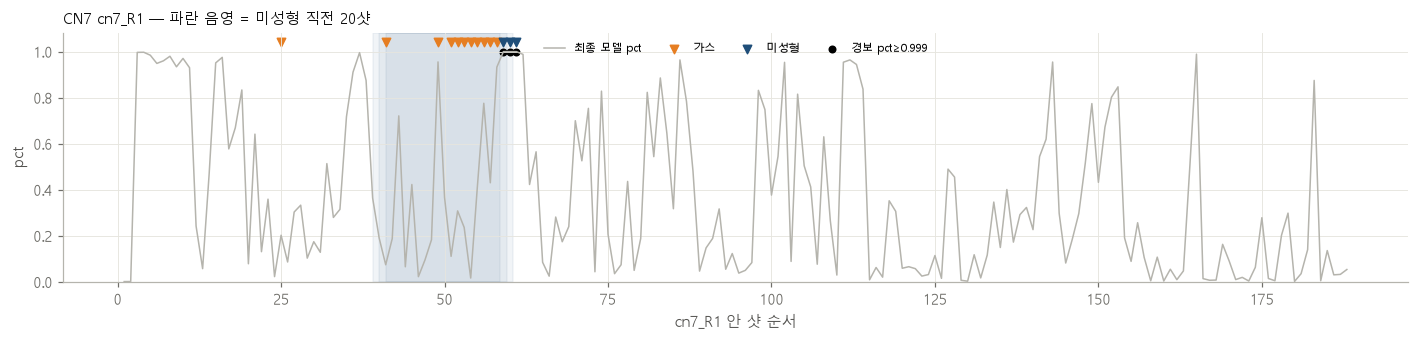

In [7]:
SG.plot_r1('cn7', k=20, q=0.999, save='./outputs/short_gas_rule/cn7_r1.png')

## 판단 기준
- **재현**: 실제 라벨 기준 가스 수가 팀원 숫자와 맞는지 (다르면 창 정의 — 미성형 샷 포함 여부, 첫 미성형만인지 — 확인)
- **우연이 아닌가**: `순열 p` < 0.05 이고, k를 바꿔도 비슷하게 유지
- **운영 가능**: 경보 기준점에서도 가스가 잡히고, 역추적 검사 샷 대비 정밀도가 무작위보다 충분히 높음
- **일반화**: 미성형 에피소드 여러 개에서 성립 (CN7은 2개뿐 → 1개에서만 성립하면 '사례 관찰'로 기술)